# 03 · BM25 — and what TF-IDF gets wrong

**Read first:** `01_theory/03_bm25.md`

1. saturation: the twentieth "Python" should not count ten times the second (`k1`)
2. explicit length normalisation (`b`)
3. BM25's own IDF — and why it needs the `+ 1`
4. an inverted index: only CVs that share a word with the job are ever touched
5. **the experiment of your project:** b = 0 vs b = 0.75

In [1]:
import csv
import math
import re
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from nltk.stem.snowball import SnowballStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP

TOKEN_PATTERN = re.compile(r"[A-Za-z֐-׿][A-Za-z0-9֐-׿+#.]*")
SCRUB = [re.compile(r"\S+@\S+\.\w+"), re.compile(r"\+?\d[\d\-\s]{7,}\d")]
stem = SnowballStemmer("english").stem

def process(text):
    for p in SCRUB:
        text = p.sub(" ", text)
    text = re.sub(r"(?<![A-Za-z])\.net\b", "dotnet", text, flags=re.I)
    toks = [t.rstrip(".").lower() for t in TOKEN_PATTERN.findall(text)]
    toks = [stem(t) for t in toks if t and (t not in STOP and len(t) > 1 or t in ("c", "go", "r"))]
    return toks + [f"{a} {b}" for a, b in zip(toks, toks[1:])]

resumes = list(csv.DictReader(open(Path("../data/resumes.csv"), encoding="utf-8")))
jobs = list(csv.DictReader(open(Path("../data/jobs.csv"), encoding="utf-8")))
docs = [process(r["text"]) for r in resumes]
ids = [r["id"] for r in resumes]

## 1. Saturation

$$ \frac{tf\,(k_1+1)}{tf + k_1} $$

The first mention says a lot, the twentieth almost nothing. The ceiling is $k_1 + 1$.

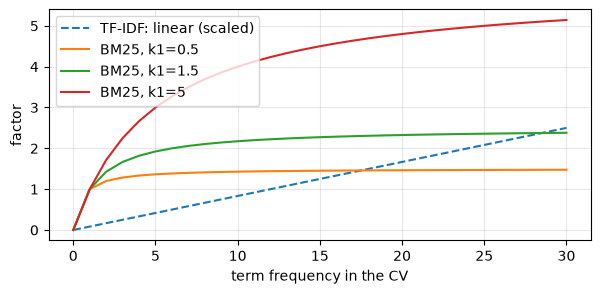

tf= 1  factor 1.00
tf= 2  factor 1.43
tf= 5  factor 1.92
tf=20  factor 2.33


In [2]:
tf = np.arange(0, 31)
plt.figure(figsize=(7, 3))
plt.plot(tf, tf / tf.max() * 2.5, "--", label="TF-IDF: linear (scaled)")
for k1 in (0.5, 1.5, 5):
    plt.plot(tf, tf * (k1 + 1) / (tf + k1), label=f"BM25, k1={k1}")
plt.xlabel("term frequency in the CV"); plt.ylabel("factor"); plt.legend(); plt.grid(alpha=.3)
plt.show()
for t in (1, 2, 5, 20):
    print(f"tf={t:2d}  factor {t * 2.5 / (t + 1.5):.2f}")

## 2. The full formula

$$ \text{score} = \sum_{t \in \text{job}} idf_{bm25}(t)\cdot\frac{tf\,(k_1+1)}{tf + k_1\,(1 - b + b\,|d|/avgdl)} $$

$$ idf_{bm25}(t) = \ln\Big(\frac{N - df + 0.5}{df + 0.5} + 1\Big) $$

Without the `+ 1`, a term in more than half the CVs gets a **negative** IDF and would *subtract* from the score:

In [3]:
N = len(docs)
for df_ in (5, 100, 150, 195):
    no_plus = math.log((N - df_ + 0.5) / (df_ + 0.5))
    with_plus = math.log((N - df_ + 0.5) / (df_ + 0.5) + 1)
    print(f"df={df_:3d}:  without +1 {no_plus:+.3f}    with +1 {with_plus:.3f}")

df=  5:  without +1 +3.571    with +1 3.599
df=100:  without +1 +0.000    with +1 0.693
df=150:  without +1 -1.092    with +1 0.289
df=195:  without +1 -3.571    with +1 0.028


## 3. The inverted index

For every term: the list of (CV row, term frequency). Ranking walks **only the job's terms**.

In [4]:
class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.doc_len = np.array([len(d) for d in docs])
        self.avgdl = self.doc_len.mean()
        self.inverted = defaultdict(list)
        for row, d in enumerate(docs):
            for term, f in Counter(d).items():
                self.inverted[term].append((row, f))
        n = len(docs)
        self.idf = {t: math.log((n - len(p) + 0.5) / (len(p) + 0.5) + 1) for t, p in self.inverted.items()}
        self.n = n

    def term_score(self, tf, doc_length, idf):
        numerator = tf * (self.k1 + 1)
        denominator = tf + self.k1 * (1 - self.b + self.b * doc_length / self.avgdl)
        return idf * numerator / denominator

    def rank(self, job_terms):
        scores = np.zeros(self.n)
        touched = set()
        for term in set(job_terms):
            for row, tf in self.inverted.get(term, []):
                scores[row] += self.term_score(tf, self.doc_len[row], self.idf[term])
                touched.add(row)
        return scores, touched

bm = BM25(docs)
job = jobs[2]
scores, touched = bm.rank(process(job["text"]))
print(job["title"], f"- touched {len(touched)} of {len(docs)} CVs")
relevant = set(job["relevant_ids"].split())
for r in np.argsort(-scores, kind="stable")[:6]:
    print(f"  {'✔' if ids[r] in relevant else ' '} {ids[r]} {resumes[r]['role']:15s} bm25 {scores[r]:6.2f}  normalised {scores[r] / scores.max():.2f}")

DevOps engineer - touched 97 of 200 CVs
    R089 sysadmin        bm25 112.80  normalised 1.00
  ✔ R133 devops          bm25  27.61  normalised 0.24
  ✔ R023 devops          bm25  24.28  normalised 0.22
  ✔ R153 devops          bm25  22.62  normalised 0.20
  ✔ R033 devops          bm25  20.73  normalised 0.18
  ✔ R163 devops          bm25  20.25  normalised 0.18


Raw BM25 scores are unbounded (6.2 here, maybe 41 for another job), so the UI divides by the best score of
the current ranking. That makes scores comparable **within one ranking only** — for research compare rank
**positions**.

Here the job shares common words ("experi", "advantag"…) with many CVs, so most of the collection is touched.
With a vocabulary of 20,000 real terms and short queries, the index skips most documents.

## 4. Saturation in action: the keyword stuffers

Some CVs repeat one skill 15 times. Compare how much the repetition buys them in TF-IDF vs BM25:

In [5]:
df_ = Counter(t for d in docs for t in set(d))
def repeated_skill(d):
    """The most repeated RARE term (in < 60 CVs), so ordinary words like 'work' are ignored."""
    counts = [(t, c) for t, c in Counter(d).items() if " " not in t and df_[t] < 60]
    return max(counts, key=lambda x: x[1]) if counts else ("", 0)

stuffers = [i for i, d in enumerate(docs) if repeated_skill(d)[1] >= 10]
print("keyword stuffers:", [ids[i] for i in stuffers])

def tf_part(tf, k1=1.5):
    return tf * (k1 + 1) / (tf + k1)

for i in stuffers[:3]:
    term, c = repeated_skill(docs[i])
    print(f"{ids[i]}: '{term}' x{c}:  TF-IDF counts it {c}x a single mention, BM25 counts it {tf_part(c):.2f} / {tf_part(1):.2f} = {tf_part(c) / tf_part(1):.1f}x")

keyword stuffers: ['R005', 'R042', 'R079', 'R116', 'R153', 'R190']
R005: 'rtos' x17:  TF-IDF counts it 17x a single mention, BM25 counts it 2.30 / 1.00 = 2.3x
R042: 'scikit' x17:  TF-IDF counts it 17x a single mention, BM25 counts it 2.30 / 1.00 = 2.3x
R079: 'network' x17:  TF-IDF counts it 17x a single mention, BM25 counts it 2.30 / 1.00 = 2.3x


## 5. The experiment: b = 0 vs b = 0.75

`b = 0` switches length normalisation off. If long CVs climb at b = 0, you have *proved* with data that length
normalisation matters. This chart is the centre of your results chapter.

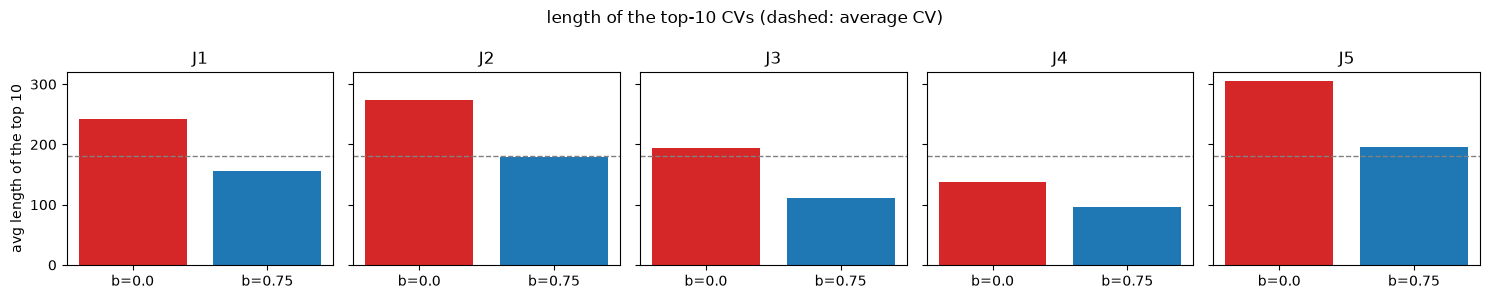

J1 b=0.0: long CVs in top 10 = 4, P@10 = 0.6 | b=0.75: long CVs in top 10 = 2, P@10 = 0.6
J2 b=0.0: long CVs in top 10 = 5, P@10 = 0.9 | b=0.75: long CVs in top 10 = 2, P@10 = 0.9
J3 b=0.0: long CVs in top 10 = 2, P@10 = 0.9 | b=0.75: long CVs in top 10 = 0, P@10 = 0.9
J4 b=0.0: long CVs in top 10 = 1, P@10 = 0.9 | b=0.75: long CVs in top 10 = 0, P@10 = 0.9
J5 b=0.0: long CVs in top 10 = 5, P@10 = 1.0 | b=0.75: long CVs in top 10 = 2, P@10 = 1.0


In [6]:
long_cut = np.percentile(bm.doc_len, 80)
fig, axes = plt.subplots(1, len(jobs), figsize=(15, 3), sharey=True)
for ax, job in zip(axes, jobs):
    q = process(job["text"])
    for b, color in ((0.0, "tab:red"), (0.75, "tab:blue")):
        s, _ = BM25(docs, b=b).rank(q)
        top10 = np.argsort(-s, kind="stable")[:10]
        ax.bar(f"b={b}", np.mean(bm.doc_len[top10]), color=color)
    ax.set_title(job["job_id"]); ax.axhline(bm.avgdl, ls="--", c="gray", lw=1)
axes[0].set_ylabel("avg length of the top 10")
plt.suptitle("length of the top-10 CVs (dashed: average CV)"); plt.tight_layout(); plt.show()

for job in jobs:
    q = process(job["text"])
    rel = set(job["relevant_ids"].split())
    line = []
    for b in (0.0, 0.75):
        s, _ = BM25(docs, b=b).rank(q)
        top10 = np.argsort(-s, kind="stable")[:10]
        line.append(f"b={b}: long CVs in top 10 = {np.sum(bm.doc_len[top10] > long_cut)}, P@10 = {np.mean([ids[r] in rel for r in top10]):.1f}")
    print(job["job_id"], " | ".join(line))

With b = 0 long CVs collect more matching words just by being long, and they climb. With b = 0.75 they pay for
their length. Look at what happens to P@10 — does length normalisation also make the ranking *better*, or only
*different*? Notebook 04 measures it properly over all jobs.

## ✍️ Try it yourself

1. Try k1 = 0.1 and k1 = 10. Which behaves like "any mention counts the same", which like TF-IDF?
2. Count how many CVs are touched for a job that says only "C++ RTOS". Why so few?
3. Try b = 1.0. Do short CVs now win too easily?

Then solve exercises 9–11 in `03_exercises/`.